# Ground Truth prüfen (ausserhalb der Kette)

**Ziel.** Der Auftraggeber setzt die Parkfelder mit dem Werkzeug aus `ground_truth_erfassen` von Hand. Bevor diese Felder als Lösungsblatt dienen, prüfen wir sie. Dieses Notebook **schaut nur hin**: Es liest die Datei des Auftraggebers und ändert sie nicht.

**Warum.** An der Ground Truth lernt das Netz, und an ihr wird es gemessen. Ein Fehler darin wandert in jedes spätere Ergebnis. Was hier auffällt, wird in `01b`, Abschnitt 10, besprochen und entschieden – nicht hier.

**Was geprüft wird.**
1. Fortschritt und Aufwand; schnell abgeschlossene leere Ausschnitte (Abschnitt 1)
2. Was gesetzt wurde: Herkunft, Form, Zustand je Bild (Abschnitt 2)
3. Was aus den Vorschlägen wurde (Abschnitt 3)
4. Kontroll-Ausschnitte: Was findet der Auftraggeber ohne Vorschlag? (Abschnitt 4)
5. Parkart: Passt die gespeicherte Angabe zum Abstand der Ringe? (Abschnitt 5)
6. Auf welchem Grund liegen die Felder: Strassenraum oder übriger Grund? (Abschnitt 6)

Das Notebook kann jederzeit neu laufen, auch mitten in der Erfassung. Verwendet werden nur **abgeschlossene** Ausschnitte: Was nicht angesehen wurde, ist keine Ground Truth. Alle Zahlen gelten für den Stand der Datei, der in Abschnitt 1 ausgegeben wird.

**Eingaben:** `daten/ground_truth/ground_truth_hand.json`, die Bildausschnitte in `daten/verarbeitet/gt_kacheln/`, Bodenbedeckung aus Notebook 00, Grundstücke der amtlichen Vermessung.
**Ausgaben:** nur Abbildungen in `ergebnisse/abbildungen/` (`gt_pruefung_…`).

In [1]:
import json                        # die Datei des Auftraggebers lesen
from pathlib import Path           # Pfade zusammensetzen

ROOT = Path.cwd().parent                             # Projektordner (eine Ebene über notebooks/)
ROH = ROOT / "daten" / "roh"                         # Rohdaten (werden nie verändert)
VERARB = ROOT / "daten" / "verarbeitet"              # abgeleitete Daten
ABB = ROOT / "ergebnisse" / "abbildungen"            # Abbildungen
HAND = ROOT / "daten" / "ground_truth" / "ground_truth_hand.json"   # die Arbeit des Auftraggebers (wird nur gelesen)
KACHEL_ORDNER = VERARB / "gt_kacheln"                # Bildausschnitte des Werkzeugs

EINST = json.loads((ROOT / "einstellungen.json").read_text(encoding="utf-8"))   # Einstellungen aus Notebook 00
CRS, GEBIET_NAME, SEED = EINST["CRS"], EINST["GEBIET_NAME"], EINST["SEED"]

import numpy as np                 # Rechnen mit Zahlenblöcken
import pandas as pd                # Tabellen
import geopandas as gpd            # Tabellen mit Geometrie
import matplotlib.pyplot as plt    # Abbildungen
from scipy.spatial import cKDTree  # findet zu jedem Punkt schnell den nächsten Nachbarn

FARBE = {"LPU": "#257de0", "QPU": "#f47230", "SCHPU": "#00b894"}   # Projektfarben je Parkart, wie in Notebook 01
print("Einstellungen aus Notebook 00: CRS =", CRS, "| Gebiet =", GEBIET_NAME, "| Seed =", SEED)

Einstellungen aus Notebook 00: CRS = EPSG:2056 | Gebiet = kreis1 | Seed = 42


## 1. Fortschritt und Aufwand

**Schritt 1: Datei lesen.** Die Datei enthält zwei Listen: die **Ausschnitte** (mit Status und Arbeitszeit) und die **Felder** (mit Lage, Parkart, Form und einem Zustand je Bild). Wir machen aus jeder Liste eine Tabelle.

Zu jedem Feld bestimmen wir den Ausschnitt, in dem es liegt: Die Koordinate wird durch die Seitenlänge eines Ausschnitts geteilt und abgerundet (`//`). Das ergibt Spalte und Zeile im Raster, genau wie in `ground_truth_erfassen`.

Vorher: eine Datei → nachher: Tabelle der Ausschnitte, Tabelle der Felder in abgeschlossenen Ausschnitten.

In [2]:
erfasst = json.loads(HAND.read_text(encoding="utf-8"))             # einmal lesen; die Datei wird nicht verändert
KACHEL_M = erfasst["einstellungen"]["kachel_m"]                    # Seitenlänge eines Ausschnitts (51,2 m)
RAND_M = erfasst["einstellungen"]["rand_m"]                        # Rand um jeden Bildausschnitt (6,4 m)
PIXEL_M = erfasst["einstellungen"]["pixel_m"]                      # Bodenauflösung der Bildausschnitte (0,05 m)
print("Stand der Datei (Weltzeit UTC):", erfasst["geaendert"])

k_tab = pd.DataFrame(erfasst["kacheln"])                           # eine Zeile je Ausschnitt
f_tab = pd.DataFrame(erfasst["felder"])                            # eine Zeile je Feld
f_tab["kachel"] = "k_" + (f_tab.x // KACHEL_M).astype(int).astype(str) + "_" + (f_tab.y // KACHEL_M).astype(int).astype(str)
f_tab["zustand_2021"] = [zustand["2021"] for zustand in f_tab.zustand]          # Zustand je Bild als eigene Spalte
f_tab["zustand_2024_25"] = [zustand["2024_25"] for zustand in f_tab.zustand]

fertig = k_tab[k_tab.status == "fertig"].copy()                    # Maske und Auswahl: nur abgeschlossene Ausschnitte
felder = f_tab[f_tab.kachel.isin(fertig.id)].copy()                # nur Felder in abgeschlossenen Ausschnitten
print(f"Ausschnitte: {len(fertig)} von {len(k_tab)} abgeschlossen ({100 * len(fertig) / len(k_tab):.0f} %)")
print(f"Felder: {len(f_tab)} in der Datei → {len(felder)} in abgeschlossenen Ausschnitten")
print(f"Arbeitszeit in abgeschlossenen Ausschnitten: {fertig.zeit_s.sum() / 60:.0f} Minuten (Pausen über 60 Sekunden zählt das Werkzeug nicht)")

Stand der Datei (Weltzeit UTC): 2026-11-27T02:11:56.513Z
Ausschnitte: 691 von 691 abgeschlossen (100 %)
Felder: 3501 in der Datei → 3492 in abgeschlossenen Ausschnitten
Arbeitszeit in abgeschlossenen Ausschnitten: 211 Minuten (Pausen über 60 Sekunden zählt das Werkzeug nicht)


**Schritt 2: Wie lange dauerte ein Ausschnitt?** Viele Ausschnitte zeigen nur Dächer, Wasser oder einen Park. Sie sind in ein, zwei Sekunden abgeschlossen. Das ist nur dann in Ordnung, wenn dort wirklich kein Parkfeld ist: Ein abgeschlossener Ausschnitt ohne Feld sagt dem Netz später "hier ist kein Parkplatz".

Die Tabelle zählt die abgeschlossenen Ausschnitte nach Dauer und danach, ob ein Feld gesetzt ist. `pd.cut` teilt die Sekunden in Klassen; `pd.crosstab` zählt jede Kombination aus.

In [3]:
gueltig = felder[~felder.geloescht & ~felder.verborgen]            # gesetzte Felder: nicht gelöscht, nicht verborgen
je_ausschnitt = gueltig.groupby("kachel").size()                   # Anzahl gesetzter Felder je Ausschnitt
fertig["felder"] = fertig.id.map(je_ausschnitt).fillna(0).astype(int)
fertig["dauer"] = pd.cut(fertig.zeit_s, [-1, 2, 5, 15, 60, 100_000], labels=["bis 2 s", "3–5 s", "6–15 s", "16–60 s", "über 60 s"])

tabelle = pd.crosstab(fertig.dauer, fertig.felder > 0, margins=True, margins_name="alle")
tabelle.rename(columns={False: "ohne Feld", True: "mit Feld"})

felder,ohne Feld,mit Feld,alle
dauer,,,
bis 2 s,236,13,249
3–5 s,72,19,91
6–15 s,23,73,96
16–60 s,5,206,211
über 60 s,0,44,44
alle,336,355,691


**Stichprobe der schnellen, leeren Ausschnitte.** Wir ziehen zwölf Ausschnitte ohne Feld, die in höchstens 2 Sekunden abgeschlossen wurden (`sample` mit festem Seed zieht immer dieselben), und zeigen sie. So kann jede Leserin selbst nachsehen, ob dort ein Parkfeld übersehen wurde.

Die kleine Funktion `zeige_ausschnitt` zeichnet einen Bildausschnitt des Werkzeugs in Landeskoordinaten. Aus dem Namen `k_<Spalte>_<Zeile>` folgt, wo der Ausschnitt liegt; das Bild reicht auf jeder Seite um den Rand weiter.

Ausschnitte ohne Feld, in höchstens 2 Sekunden abgeschlossen: 236


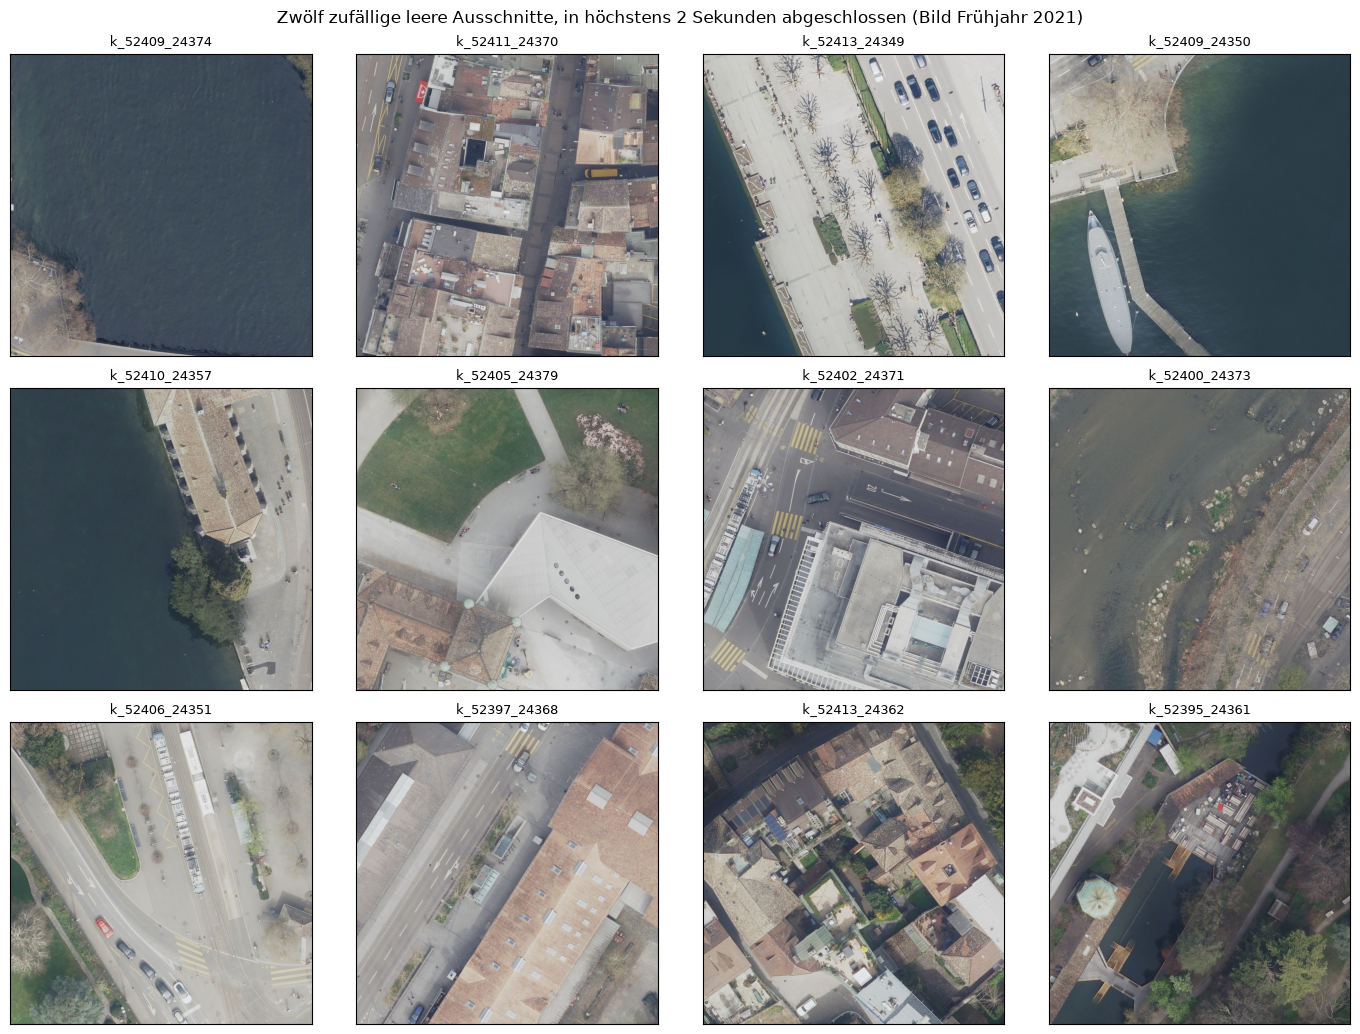

In [4]:
def zeige_ausschnitt(ax, kachel_id, aufnahme="2021"):
    # Zeichnet das Bild eines Ausschnitts so, dass die Achsen Landeskoordinaten in Metern sind.
    spalte, zeile = (int(teil) for teil in kachel_id.split("_")[1:])   # "k_52400_24357" -> 52400, 24357
    bild = plt.imread(KACHEL_ORDNER / aufnahme / f"{kachel_id}.jpg")
    links = spalte * KACHEL_M - RAND_M                                 # linker Bildrand in Metern
    oben = (zeile + 1) * KACHEL_M + RAND_M                             # oberer Bildrand in Metern
    seite = bild.shape[0] * PIXEL_M                                    # Seitenlänge des Bildes in Metern
    ax.imshow(bild, extent=[links, links + seite, oben - seite, oben])
    ax.set_xticks([]); ax.set_yticks([])                               # keine Achsenbeschriftung

schnell_leer = fertig[(fertig.felder == 0) & (fertig.zeit_s <= 2)]
print(f"Ausschnitte ohne Feld, in höchstens 2 Sekunden abgeschlossen: {len(schnell_leer)}")
probe = schnell_leer.sample(min(12, len(schnell_leer)), random_state=SEED)

fig, achsen = plt.subplots(3, 4, figsize=(14, 10.5))
for ax in achsen.ravel():
    ax.axis("off")                                                     # leere Plätze bleiben weiss
for ax, kachel_id in zip(achsen.ravel(), probe.id):
    ax.axis("on")
    zeige_ausschnitt(ax, kachel_id)
    ax.set_title(kachel_id, fontsize=9)
fig.suptitle("Zwölf zufällige leere Ausschnitte, in höchstens 2 Sekunden abgeschlossen (Bild Frühjahr 2021)")
fig.tight_layout()
fig.savefig(ABB / "gt_pruefung_leere_ausschnitte.png", dpi=110, bbox_inches="tight")
plt.show()

**Was die Abbildung zeigt.** Jedes Bild ist ein ganzer Ausschnitt von 64 × 64 m (51,2 m plus Rand). Ist auf einem dieser Bilder ein aufgemaltes Parkfeld zu sehen, wurde es übersehen; der Ausschnitt gehört dann im Werkzeug nochmals geöffnet.

**Schritt 3: Welche Fläche ist erfasst?** Das Werkzeug zeigt nur Ausschnitte, in denen eine öffentliche Verkehrsfläche oder ein DAV-Feld liegt (`ground_truth_erfassen`, Abschnitt 2). Zwei Fragen:
- Wie viel vom Gebiet liegt in einem Ausschnitt? Was in keinem liegt, wurde nie angesehen und ist keine Ground Truth.
- Ragen Ausschnitte über die Gebietsgrenze hinaus? Dort gesetzte Felder liegen ausserhalb des Gebiets.

`box(links, unten, rechts, oben)` macht aus vier Koordinaten ein Quadrat; `intersection` schneidet es mit dem Gebiet.

Vorher: Liste der Ausschnitte → nachher: je Ausschnitt die Fläche, die im Gebiet liegt.

In [5]:
from shapely.geometry import box                                   # Rechteck aus vier Koordinaten

gebiet = gpd.read_file(VERARB / "gebiet.geojson")                  # Tabelle mit einer Zeile: das Gebiet (Notebook 00)
gebiet_flaeche = gebiet.geometry.iloc[0]                           # die Fläche selbst
quadrate = gpd.GeoSeries([box(i * KACHEL_M, j * KACHEL_M, (i + 1) * KACHEL_M, (j + 1) * KACHEL_M)
                          for i, j in zip(k_tab.i, k_tab.j)], crs=CRS)          # ein Quadrat je Ausschnitt
im_gebiet = quadrate.intersection(gebiet_flaeche).area             # Fläche jedes Ausschnitts, die im Gebiet liegt

print(f"Gebiet: {gebiet_flaeche.area / 1e6:.2f} km² | alle {len(k_tab)} Ausschnitte zusammen: {quadrate.area.sum() / 1e6:.2f} km²")
print(f"Vom Gebiet liegen {100 * im_gebiet.sum() / gebiet_flaeche.area:.0f} % in einem Ausschnitt; der Rest wurde nicht gezeigt")
print(f"Ausschnitte, die über die Gebietsgrenze ragen: {int((im_gebiet < 0.999 * quadrate.area).sum())} von {len(k_tab)}")

lage_gesetzt = gpd.GeoSeries(gpd.points_from_xy(gueltig.x, gueltig.y), crs=CRS)   # gesetzte Felder als Punkte
ausserhalb = ~lage_gesetzt.within(gebiet_flaeche).values           # True, wenn ein Feld ausserhalb des Gebiets liegt
print(f"Gesetzte Felder: {len(gueltig)} → davon ausserhalb des Gebiets: {int(ausserhalb.sum())} ({100 * ausserhalb.mean():.0f} %)")

Gebiet: 1.80 km² | alle 691 Ausschnitte zusammen: 1.81 km²
Vom Gebiet liegen 91 % in einem Ausschnitt; der Rest wurde nicht gezeigt
Ausschnitte, die über die Gebietsgrenze ragen: 133 von 691
Gesetzte Felder: 3269 → davon ausserhalb des Gebiets: 428 (13 %)


## 2. Was wurde gesetzt?

Jedes Feld der Datei gehört zu genau einer von vier Gruppen. `np.select` prüft die Bedingungen der Reihe nach und vergibt den ersten passenden Namen.

| Gruppe | Bedeutung |
| --- | --- |
| DAV, übernommen | Vorschlag aus der DAV, vom Auftraggeber behalten (vielleicht verschoben oder umgestellt) |
| DAV, gelöscht | Vorschlag aus der DAV, vom Auftraggeber gelöscht: in keinem Bild ein Feld |
| DAV, verborgen | Vorschlag in einem Kontroll-Ausschnitt; er wurde **nicht gezeigt** (Abschnitt 4) |
| neu gesetzt | vom Auftraggeber selbst gesetzt |

Vorher: alle Felder in abgeschlossenen Ausschnitten → nachher: Anzahl je Gruppe.

In [6]:
felder["gruppe"] = np.select([felder.verborgen, felder.geloescht, felder.herkunft == "DAV"],
                             ["DAV, verborgen", "DAV, gelöscht", "DAV, übernommen"], default="neu gesetzt")
print(f"Vorher: {len(felder)} Felder in abgeschlossenen Ausschnitten → nachher:")
print(felder.gruppe.value_counts().to_string())

gueltig = felder[felder.gruppe.isin(["DAV, übernommen", "neu gesetzt"])].copy()   # das sind die gesetzten Felder
print(f"\nGesetzte Felder (übernommen oder neu): {len(gueltig)}")

Vorher: 3492 Felder in abgeschlossenen Ausschnitten → nachher:
gruppe
neu gesetzt        2240
DAV, übernommen    1029
DAV, verborgen      203
DAV, gelöscht        20

Gesetzte Felder (übernommen oder neu): 3269


**Form und Zustand der gesetzten Felder.** Die Wörter für den Zustand sind dieselben wie in der Sichtprüfung (`01b`, Abschnitt 9). Die Wörter für die Form hat der Auftraggeber beim Erfassen anders verwendet; das steht gleich nach der Tabelle. Für das Lösungsblatt heisst das später: `sichtbar` → Parkfläche; `verdeckt` und `unsicher` → wird nicht bewertet; `kein Parkfeld` → kein Parkplatz.

In [7]:
print(pd.crosstab(gueltig.form, gueltig.gruppe, margins=True, margins_name="alle").to_string())
print()
zustaende = pd.DataFrame({"Frühjahr 2021": gueltig.zustand_2021.value_counts(),
                          "Sommer 2024/25": gueltig.zustand_2024_25.value_counts()}).fillna(0).astype(int)
zustaende

gruppe                      DAV, übernommen  neu gesetzt  alle
form                                                          
Einzelfeld                              890         1779  2669
Streifen ohne Einzelfelder               12          197   209
gelbes Feld mit Kreuz                   116          245   361
unklar                                   11           19    30
alle                                   1029         2240  3269



,Frühjahr 2021,Sommer 2024/25
sichtbar,2990,2014
verdeckt,168,953
unsicher,68,184
kein Parkfeld,43,118


**Wie der Auftraggeber die Formen verwendet hat** (Angabe vom 27.11.2026, `01b`, Abschnitt 10.1). In der Datei stehen die Namen des Werkzeugs; gemeint ist:

| Zeichen im Werkzeug | Name in der Datei | vom Auftraggeber verwendet für |
| --- | --- | --- |
| L, Q, S | `Einzelfeld` | gewöhnliches Feld |
| ✕ | `gelbes Feld mit Kreuz` | Taxi, Polizei und jedes Feld mit aufgemaltem Kreuz |
| ? | `unklar` | Invalidenparkplatz |
| ═ | `Streifen ohne Einzelfelder` | Linie oder durchgezogener Parkbereich; so viele Ringe, wie nach seiner Schätzung Autos Platz haben |

**Gegenprobe an den übernommenen DAV-Feldern.** Bei ihnen kennen wir die **Art** der DAV (`Standard`, `Taxi`, `Polizei`, `Invalid` …, Notebook 01). `map` schlägt die Art über die Kennung des Feldes nach. Die Kreuztabelle zeigt, welche Form der Auftraggeber den Feldern jeder Art gegeben hat.

Vorher: übernommene DAV-Felder → nachher: dieselben Felder mit der Art der DAV.

In [8]:
art_je_feld = gpd.read_file(VERARB / "dav_punkte.gpkg", ignore_geometry=True).set_index("id").art   # Nachschlagetabelle: Kennung -> Art
uebernommene = gueltig[gueltig.gruppe == "DAV, übernommen"].copy()
uebernommene["art_dav"] = uebernommene.id.map(art_je_feld)         # Art der DAV über die Kennung nachschlagen
print(f"Vorher: {len(uebernommene)} übernommene DAV-Felder → nachher: {int(uebernommene.art_dav.notna().sum())} mit Art der DAV")
pd.crosstab(uebernommene.art_dav.rename("Art der DAV"), uebernommene.form, margins=True, margins_name="alle")

Vorher: 1029 übernommene DAV-Felder → nachher: 1029 mit Art der DAV


form,Einzelfeld,Streifen ohne Einzelfelder,gelbes Feld mit Kreuz,unklar,alle
Art der DAV,,,,,
Car,0,0,9,0,9
Elektro,4,0,0,0,4
Güter / Taxi,1,0,3,0,4
Güterumschlag,11,0,23,0,34
Invalid,15,0,0,6,21
Polizei,4,0,13,0,17
Standard,837,7,2,2,848
Taxi,18,5,66,3,92
alle,890,12,116,11,1029


**Wie man die Tabelle liest.** Jede Zeile ist eine Art der DAV, jede Spalte eine Form im Werkzeug. Stehen die Taxi- und Polizeifelder überwiegend unter `gelbes Feld mit Kreuz` und die Standard-Felder unter `Einzelfeld`, passt die Angabe des Auftraggebers zu den amtlichen Daten. Die Form beschreibt, **wie die Markierung aussieht**; eine amtliche Kategorie ist sie nicht.

## 3. Was wurde aus den Vorschlägen?

Das Werkzeug schlägt jedes DAV-Feld an der Stelle des DAV-Punktes vor, und unter einer Baumkrone (Pflanzenindex NDVI über 0,1 im Sommerbild) den Zustand `verdeckt`. Der Vorschlag bleibt bei jedem Feld gespeichert. So lässt sich nachzählen, was der Auftraggeber geändert hat.

**Schritt 1: verschoben.** `np.hypot(dx, dy)` ist der Abstand zwischen vorgeschlagener und gesetzter Lage (Satz des Pythagoras). Als verschoben gilt ein Feld ab 5 cm.

In [9]:
uebernommen = gueltig[gueltig.gruppe == "DAV, übernommen"].copy()
vorschlag = pd.json_normalize(uebernommen.vorschlag.tolist()).set_index(uebernommen.index)   # Vorschlag als Spalten: x, y, parkart, zustand.2021, …
uebernommen["verschiebung_m"] = np.hypot(uebernommen.x - vorschlag.x, uebernommen.y - vorschlag.y)
verschoben = uebernommen[uebernommen.verschiebung_m > 0.05]
print(f"Übernommene Vorschläge: {len(uebernommen)} → davon verschoben: {len(verschoben)} ({100 * len(verschoben) / len(uebernommen):.0f} %)")
print("Verschiebung der verschobenen Felder in Metern:")
verschoben.verschiebung_m.describe(percentiles=[0.25, 0.5, 0.75, 0.95]).round(2).to_frame().T

Übernommene Vorschläge: 1029 → davon verschoben: 223 (22 %)


Verschiebung der verschobenen Felder in Metern:


,count,mean,std,min,25%,50%,75%,95%,max
verschiebung_m,223.0,2.32,3.78,0.22,0.92,1.58,2.32,4.89,35.61


**Schritt 2: Zustand im Sommerbild.** Die Kreuztabelle stellt den Vorschlag (Zeilen) dem Entscheid des Auftraggebers (Spalten) gegenüber. Sie zeigt, wie gut die einfache Regel "Baumkrone aus dem Infrarot" sein Urteil trifft. In `ground_truth_erfassen`, Abschnitt 3, wurde dieselbe Regel an den 20 Feldern der Sichtprüfung kontrolliert; hier steht dieselbe Frage für alle übernommenen Felder.

In [10]:
kreuz = pd.crosstab(vorschlag["zustand.2024_25"].rename("Vorschlag"), uebernommen.zustand_2024_25.rename("Entscheid"),
                    margins=True, margins_name="alle")
display(kreuz)
entschieden_verdeckt = uebernommen.zustand_2024_25 == "verdeckt"
vorgeschlagen_verdeckt = vorschlag["zustand.2024_25"] == "verdeckt"
print(f"Als verdeckt entschieden: {entschieden_verdeckt.sum()} → davon hatte das Werkzeug vorgeschlagen: "
      f"{(entschieden_verdeckt & vorgeschlagen_verdeckt).sum()} ({100 * (entschieden_verdeckt & vorgeschlagen_verdeckt).sum() / max(entschieden_verdeckt.sum(), 1):.0f} %)")

Entscheid,kein Parkfeld,sichtbar,unsicher,verdeckt,alle
Vorschlag,,,,,
sichtbar,10,690,77,81,858
verdeckt,2,3,2,164,171
alle,12,693,79,245,1029


Als verdeckt entschieden: 245 → davon hatte das Werkzeug vorgeschlagen: 164 (67 %)


## 4. Kontroll-Ausschnitte

In einem Zehntel der Ausschnitte mit DAV-Feldern zeigt das Werkzeug **keinen** Vorschlag. Dort setzt der Auftraggeber alles selbst. Jetzt halten wir die verborgenen Vorschläge dagegen: Wie viele DAV-Felder hat er gefunden, ohne sie zu sehen?

Ein gesetztes Feld gilt als **dasselbe** wie ein verborgenes DAV-Feld, wenn beide nahe beieinanderliegen. Vor der Erfassung war dafür 1,5 m festgelegt (etwa eine halbe Feldbreite). Abschnitt 3 zeigt aber: Der DAV-Punkt liegt oft nicht in der Feldmitte, sondern wurde um ein bis zwei Meter verschoben. Darum stehen hier **drei** Grenzen nebeneinander. Die festgelegte bleibt die Hauptzahl, die beiden anderen zeigen, wie stark das Ergebnis an der Grenze hängt.

`cKDTree(...).query(...)` liefert zu jedem verborgenen Feld den Abstand zum nächsten gesetzten Feld.

In [11]:
kontroll_ids = fertig[fertig.blind].id                             # abgeschlossene Kontroll-Ausschnitte
verborgen = felder[felder.verborgen & felder.kachel.isin(kontroll_ids)]
neu_gesetzt = gueltig[gueltig.herkunft == "neu"]                   # alle selbst gesetzten Felder (auch im Nachbarausschnitt)
print(f"Abgeschlossene Kontroll-Ausschnitte: {len(kontroll_ids)} von {int(k_tab.blind.sum())} | verborgene DAV-Felder darin: {len(verborgen)}")

if len(verborgen) and len(neu_gesetzt):
    abstand, _ = cKDTree(neu_gesetzt[["x", "y"]].values).query(verborgen[["x", "y"]].values)   # je verborgenes Feld: nächstes gesetztes
    for grenze in [1.5, 2.5, 3.5]:
        gefunden = int((abstand <= grenze).sum())
        print(f"  gefunden innerhalb {grenze} m: {gefunden} von {len(verborgen)} ({100 * gefunden / len(verborgen):.0f} %)")
    nicht = verborgen.assign(abstand_m=abstand.round(1))[abstand > 3.5]
    print(f"\nNicht gefunden (kein gesetztes Feld innerhalb 3,5 m): {len(nicht)}. Je Ausschnitt:")
    print(nicht.groupby("kachel").size().rename("felder").to_string() if len(nicht) else "  keine")

Abgeschlossene Kontroll-Ausschnitte: 20 von 20 | verborgene DAV-Felder darin: 203
  gefunden innerhalb 1.5 m: 167 von 203 (82 %)
  gefunden innerhalb 2.5 m: 187 von 203 (92 %)
  gefunden innerhalb 3.5 m: 192 von 203 (95 %)

Nicht gefunden (kein gesetztes Feld innerhalb 3,5 m): 11. Je Ausschnitt:
kachel
k_52398_24360    1
k_52400_24357    1
k_52403_24364    1
k_52408_24372    8


**Wie man das liest.** Ein hoher Anteil heisst: Der Auftraggeber findet die Felder auch ohne Vorschlag; die Vorschläge lenken sein Urteil also wenig. Die nicht gefundenen Felder sind kein Beweis für einen Fehler des Auftraggebers: Ein DAV-Feld kann im Bild verdeckt oder nicht mehr aufgemalt sein. Diese Ausschnitte sind es wert, einzeln angesehen zu werden.

## 5. Parkart: Passt die gespeicherte Angabe zum Abstand der Ringe?

**Worum es geht.** Im Werkzeug trägt jedes Feld eine Parkart: `L` längs (Autos hintereinander), `Q` quer (Autos nebeneinander), `S` schräg. Aus ihr folgt später die Tiefe des Kästchens (`01b`, Abschnitt 1). Die Angabe lässt sich an etwas prüfen, das nicht von der gedrückten Taste abhängt: am **Abstand zum nächsten Ring**. Felder nebeneinander liegen etwa 2,5 m auseinander, Felder hintereinander etwa 6 m.

**Schritt 1: Woher kommt eine Grenze?** Wir messen zuerst an den **DAV-Punkten** (alle 1'252 im Gebiet, an der amtlichen Lage), wie weit der nächste DAV-Punkt entfernt ist, getrennt nach der Parkart der DAV. `query(..., k=2)` liefert die zwei nächsten Punkte; der erste ist der Punkt selbst (Abstand 0), der zweite sein Nachbar.

In [12]:
dav_alle = f_tab[f_tab.herkunft == "DAV"].copy()                   # alle DAV-Felder der Datei, auch in offenen Ausschnitten
amtlich = pd.json_normalize(dav_alle.vorschlag.tolist()).set_index(dav_alle.index)   # amtliche Lage und Parkart
abstand, _ = cKDTree(amtlich[["x", "y"]].values).query(amtlich[["x", "y"]].values, k=2)
amtlich["nachbar_m"] = abstand[:, 1]                               # Spalte 0 ist der Punkt selbst
print(f"{len(amtlich)} DAV-Punkte: Abstand zum nächsten DAV-Punkt in Metern, je Parkart der DAV")
amtlich.groupby("parkart").nachbar_m.describe(percentiles=[0.05, 0.5, 0.95]).round(2)

1252 DAV-Punkte: Abstand zum nächsten DAV-Punkt in Metern, je Parkart der DAV


,count,mean,std,min,5%,50%,95%,max
parkart,,,,,,,,
LPU,709.0,7.25,10.50,2.33,4.29,5.84,9.46,154.12
QPU,262.0,2.50,0.54,2.01,2.13,2.41,2.77,8.18
SCHPU,281.0,2.96,0.47,2.15,2.57,2.88,3.60,5.66


**Die Regel.** Aus der Tabelle lesen wir zwei Grenzen ab und halten sie fest (sie gelten für den Rest des Notebooks):

| Abstand zum nächsten Ring | Aussage der Regel |
| --- | --- |
| unter 4 m | `eng`: quer oder schräg (der Abstand trennt diese beiden nicht) |
| 4 bis 9 m | `weit`: längs |
| über 9 m | `einzeln`: keine Aussage |

**Schritt 2: Wie gut ist die Regel?** Wir prüfen sie an den übernommenen DAV-Feldern, und zwar an der Lage, die der Auftraggeber gesetzt hat. Als Vergleich dient die Parkart der **DAV** (nicht die im Werkzeug gespeicherte).

Vorher: gesetzte Felder → nachher: je Feld der Abstand zum nächsten gesetzten Feld und die Aussage der Regel.

In [13]:
ENG_M, EINZELN_M = 4.0, 9.0                                        # die beiden Grenzen der Regel in Metern

abstand, _ = cKDTree(gueltig[["x", "y"]].values).query(gueltig[["x", "y"]].values, k=2)
gueltig["nachbar_m"] = abstand[:, 1]                               # Abstand zum nächsten gesetzten Feld
gueltig["regel"] = np.select([gueltig.nachbar_m < ENG_M, gueltig.nachbar_m <= EINZELN_M], ["eng", "weit"], default="einzeln")

uebernommen = gueltig[gueltig.gruppe == "DAV, übernommen"].copy()
uebernommen["parkart_dav"] = [v["parkart"] for v in uebernommen.vorschlag]      # Parkart laut DAV
kreuz = pd.crosstab(uebernommen.parkart_dav.rename("Parkart der DAV"), uebernommen.regel.rename("Regel"))
display(kreuz)
for parkart, erwartet in [("LPU", "weit"), ("QPU", "eng"), ("SCHPU", "eng")]:
    zeile = kreuz.loc[parkart]
    mit_nachbar = zeile.sum() - zeile.get("einzeln", 0)            # einzeln stehende Felder zählen nicht mit
    print(f"{parkart}: Regel sagt '{erwartet}' bei {zeile.get(erwartet, 0)} von {mit_nachbar} Feldern mit Nachbar ({100 * zeile.get(erwartet, 0) / mit_nachbar:.0f} %)")

Regel,einzeln,eng,weit
Parkart der DAV,,,
LPU,37,30,544
QPU,0,186,5
SCHPU,0,225,2


LPU: Regel sagt 'weit' bei 544 von 574 Feldern mit Nachbar (95 %)
QPU: Regel sagt 'eng' bei 186 von 191 Feldern mit Nachbar (97 %)
SCHPU: Regel sagt 'eng' bei 225 von 227 Feldern mit Nachbar (99 %)


**Schritt 3: die gespeicherte Parkart der neu gesetzten Felder.** Jetzt dieselbe Messung für die Felder, die der Auftraggeber selbst gesetzt hat (nur Form `Einzelfeld`). Das Histogramm zeigt die Abstände, getrennt nach der **gespeicherten** Parkart. Stimmt die Angabe, liegt der Berg von `L` bei etwa 6 m und der Berg von `Q` bei etwa 2,5 m.

Neu gesetzte Einzelfelder: Abstand zum nächsten Ring in Metern, je gespeicherter Parkart


,count,mean,std,min,25%,50%,75%,max
parkart,,,,,,,,
LPU,681.0,2.61,2.31,1.59,2.17,2.37,2.57,56.58
QPU,549.0,5.37,2.00,0.91,4.73,5.25,5.82,28.82
SCHPU,549.0,2.77,0.94,1.71,2.35,2.56,2.85,15.12


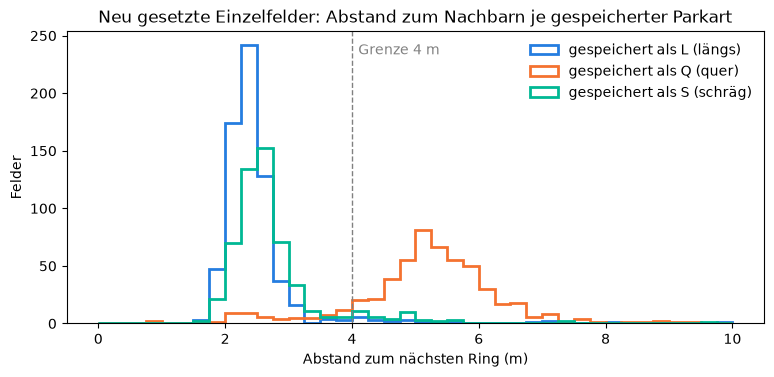

Gespeicherte Parkart (Zeilen) gegen die Aussage der Regel (Spalten):


regel,einzeln,eng,weit,alle
parkart,,,,
LPU,5,654,22,681
QPU,13,61,475,549
SCHPU,2,506,41,549
alle,20,1221,538,1779


In [14]:
neu_einzel = gueltig[(gueltig.herkunft == "neu") & (gueltig.form == "Einzelfeld")]
print("Neu gesetzte Einzelfelder: Abstand zum nächsten Ring in Metern, je gespeicherter Parkart")
display(neu_einzel.groupby("parkart").nachbar_m.describe(percentiles=[0.25, 0.5, 0.75]).round(2))

fig, ax = plt.subplots(figsize=(9, 3.8))
klassen = np.arange(0, 10.25, 0.25)                                # Klassen von 25 cm bis 10 m
for parkart, name in [("LPU", "gespeichert als L (längs)"), ("QPU", "gespeichert als Q (quer)"), ("SCHPU", "gespeichert als S (schräg)")]:
    ax.hist(neu_einzel[neu_einzel.parkart == parkart].nachbar_m, bins=klassen, histtype="step", linewidth=2, color=FARBE[parkart], label=name)
ax.axvline(ENG_M, color="grey", linestyle="--", linewidth=1)       # Grenze der Regel
ax.text(ENG_M + 0.1, ax.get_ylim()[1] * 0.92, "Grenze 4 m", color="grey")
ax.set_xlabel("Abstand zum nächsten Ring (m)")
ax.set_ylabel("Felder")
ax.set_title("Neu gesetzte Einzelfelder: Abstand zum Nachbarn je gespeicherter Parkart")
ax.legend(frameon=False)
fig.savefig(ABB / "gt_pruefung_parkart_abstand.png", dpi=130, bbox_inches="tight")
plt.show()

print("Gespeicherte Parkart (Zeilen) gegen die Aussage der Regel (Spalten):")
pd.crosstab(neu_einzel.parkart, neu_einzel.regel, margins=True, margins_name="alle")

**Was die Abbildung zeigt.** Jede Linie ist die Verteilung der Abstände für eine gespeicherte Parkart. Liegt der Berg der als `L` gespeicherten Felder links der Grenze und jener der als `Q` gespeicherten rechts davon, sind längs und quer vertauscht gespeichert.

**Schritt 4: Beispiele im Bild.** Zahlen überzeugen weniger als ein Blick aufs Bild. Wir ziehen je vier neu gesetzte Felder, die als `L` und als `Q` gespeichert sind (fester Seed, höchstens eines je Ausschnitt), und zeigen 22 × 22 m um das Feld. Die Ringe tragen den gespeicherten Buchstaben.

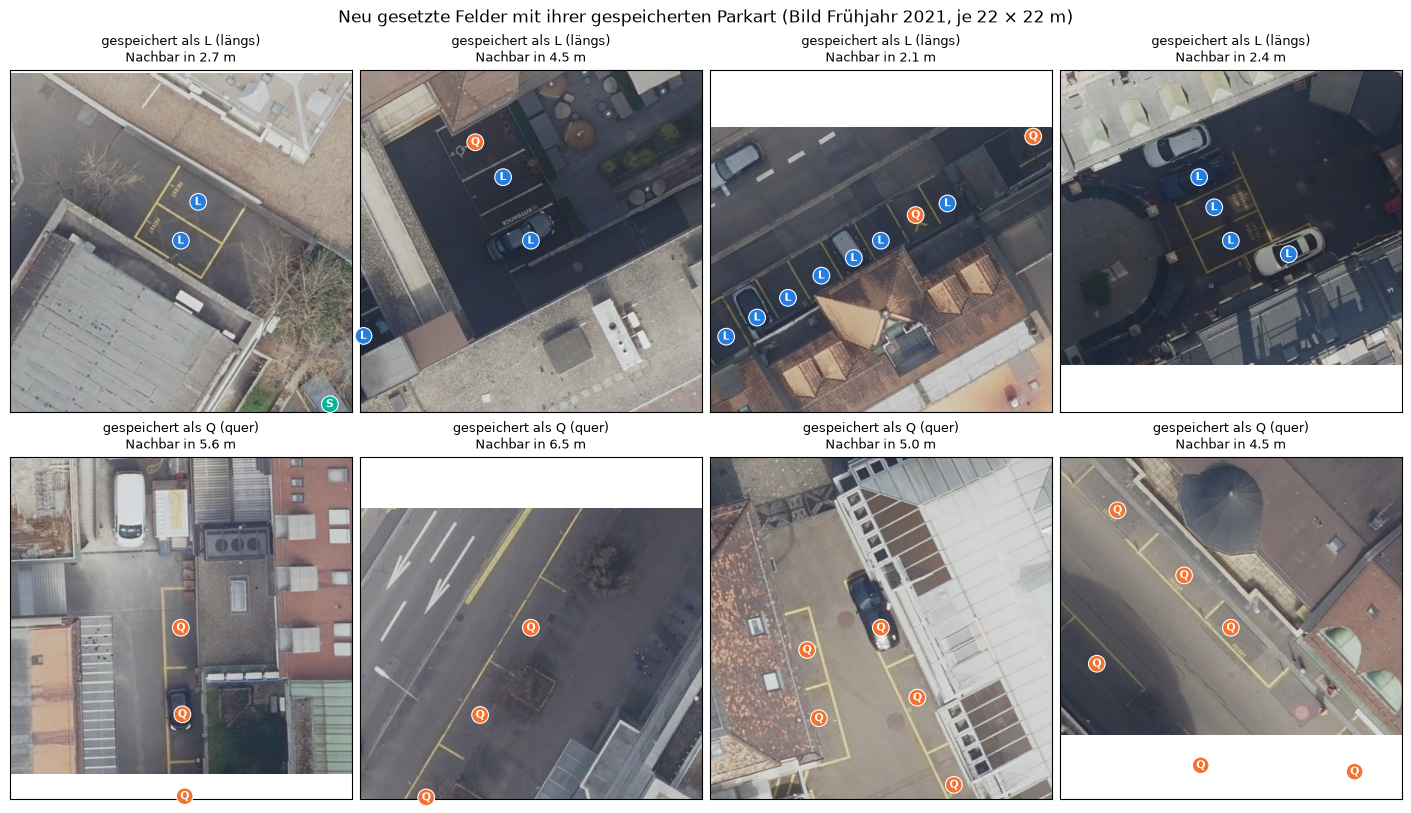

In [15]:
def zeige_feld(ax, feld, halb=11):
    # Zeigt die Umgebung eines Feldes (2 × halb Meter) mit allen gesetzten Ringen und ihrem gespeicherten Buchstaben.
    zeige_ausschnitt(ax, feld.kachel)
    nahe = gueltig[(abs(gueltig.x - feld.x) < halb) & (abs(gueltig.y - feld.y) < halb)]
    for nachbar in nahe.itertuples():
        ax.text(nachbar.x, nachbar.y, nachbar.parkart[0], color="white", ha="center", va="center", fontsize=8, fontweight="bold",
                bbox=dict(boxstyle="circle,pad=0.25", facecolor=FARBE[nachbar.parkart], edgecolor="white", linewidth=0.8))
    ax.set_xlim(feld.x - halb, feld.x + halb)
    ax.set_ylim(feld.y - halb, feld.y + halb)

fig, achsen = plt.subplots(2, 4, figsize=(14, 8), layout="constrained")   # "constrained": Titel und Bilder überlappen nicht
for zeile, (parkart, name) in enumerate([("LPU", "gespeichert als L (längs)"), ("QPU", "gespeichert als Q (quer)")]):
    auswahl = neu_einzel[(neu_einzel.parkart == parkart) & (neu_einzel.regel != "einzeln")]
    auswahl = auswahl.groupby("kachel").sample(1, random_state=SEED)           # höchstens ein Beispiel je Ausschnitt
    auswahl = auswahl.sample(min(4, len(auswahl)), random_state=SEED)
    for ax, feld in zip(achsen[zeile], auswahl.itertuples()):
        zeige_feld(ax, feld)
        ax.set_title(f"{name}\nNachbar in {feld.nachbar_m:.1f} m", fontsize=9)
fig.suptitle("Neu gesetzte Felder mit ihrer gespeicherten Parkart (Bild Frühjahr 2021, je 22 × 22 m)")
fig.savefig(ABB / "gt_pruefung_parkart_beispiele.png", dpi=110, bbox_inches="tight")
plt.show()

**Was die Abbildung zeigt.** Obere Reihe: Felder, die als längs gespeichert sind. Untere Reihe: Felder, die als quer gespeichert sind. Stehen die Autos oben **nebeneinander** und unten **hintereinander**, ist die Angabe vertauscht.

**Schritt 5: die übernommenen DAV-Felder.** Bei ihnen kennen wir die Parkart der DAV. Die Kreuztabelle zeigt, wie oft der Auftraggeber sie umgestellt hat.

In [16]:
print("Parkart der DAV (Zeilen) gegen die im Werkzeug gespeicherte Parkart (Spalten), übernommene DAV-Felder:")
pd.crosstab(uebernommen.parkart_dav.rename("Parkart der DAV"), uebernommen.parkart.rename("gespeichert"), margins=True, margins_name="alle")

Parkart der DAV (Zeilen) gegen die im Werkzeug gespeicherte Parkart (Spalten), übernommene DAV-Felder:


gespeichert,LPU,QPU,SCHPU,alle
Parkart der DAV,,,,
LPU,198,413,0,611
QPU,155,36,0,191
SCHPU,0,0,227,227
alle,353,449,227,1029


## 6. Auf welchem Grund liegen die Felder?

**Worum es geht.** Der Auftraggeber setzt **jedes** aufgemalte Feld, auch in Innenhöfen (`01b`, 10.1). Die DAV führt nur öffentlich zugängliche Felder. Für den Vergleich mit der DAV muss man die beiden Arten trennen können. Notebook 01, Abschnitt 14, hat gezeigt, auf welchen Grundstücken die DAV-Felder liegen. Hier steht dieselbe Auszählung für die von Hand gesetzten Felder daneben. Entschieden wird nichts; die Regeln A, B und C sind die drei Möglichkeiten aus `01b`, Abschnitt 10.3.

**Schritt 1: Bodenbedeckung und Grundstück je Feld.** Wie in Notebook 01: `sjoin` hängt an jeden Punkt die Fläche, in der er liegt. Die DAV-Felder nehmen wir an ihrer **amtlichen** Lage (alle 1'252), die neu gesetzten an der gesetzten Lage (abgeschlossene Ausschnitte).

In [17]:
bo = gpd.read_file(VERARB / f"bodenbedeckung_{GEBIET_NAME}.gpkg")[["art_txt", "geometry"]]             # Bodenbedeckung (Notebook 00)
grundstuecke = gpd.read_file(ROH / "vermessung/av_li_liegenschaft_a_kreis1.geojson").to_crs(CRS)[["nummer", "geometry"]]

punkte_dav = gpd.GeoDataFrame({"quelle": "DAV (amtliche Lage)", "form": "", "kachel": ""}, index=amtlich.index, geometry=gpd.points_from_xy(amtlich.x, amtlich.y), crs=CRS)
neu = gueltig[gueltig.herkunft == "neu"]
punkte_neu = gpd.GeoDataFrame({"quelle": "neu gesetzt", "form": neu.form, "kachel": neu.kachel}, index=neu.index, geometry=gpd.points_from_xy(neu.x, neu.y), crs=CRS)
punkte = pd.concat([punkte_dav, punkte_neu]).reset_index(drop=True)             # beide Gruppen untereinander

punkte = gpd.sjoin(punkte, bo, how="left", predicate="within").drop(columns="index_right")              # Bodenbedeckung unter dem Punkt
punkte = gpd.sjoin(punkte, grundstuecke, how="left", predicate="within").drop(columns="index_right")    # Grundstück unter dem Punkt
punkte = punkte[~punkte.index.duplicated()]                        # liegt ein Punkt genau auf einer Grenze, zählt er nur einmal
print(punkte.quelle.value_counts().to_string())
print("\nBodenbedeckung unter dem Feld:")
pd.crosstab(punkte.art_txt, punkte.quelle).sort_values("neu gesetzt", ascending=False)

quelle
neu gesetzt            2240
DAV (amtliche Lage)    1252

Bodenbedeckung unter dem Feld:


quelle,DAV (amtliche Lage),neu gesetzt
art_txt,,
befestigt.uebrige_befestigte.Hausumschwung,5,1069
befestigt.Strasse_Weg.Strasse,1023,793
befestigt.uebrige_befestigte.Parkplatz,122,152
befestigt.Trottoir,89,136
befestigt.Strasse_Weg.Velo_Fussweg,11,45
humusiert.Gartenanlage.Gartenanlage_Hausumschwung,0,23
Gebaeude.Gastgewerbe,0,10
humusiert.uebrige_humusierte.Verkehrsteilerflaeche,0,8
Gebaeude.Verwaltung,0,4


**Schritt 2: Woraus besteht das Grundstück?** Wie in Notebook 01, Abschnitt 14: Grundstücke mit der Bodenbedeckung verschneiden (`overlay`), die Arten zu drei Gruppen zusammenfassen und je Grundstück die Anteile rechnen.

Vorher: Grundstücke mit mindestens einem Feld → nachher: je Grundstück der Anteil Strassenraum und der Anteil Gebäude.

In [18]:
betroffen = grundstuecke[grundstuecke.nummer.isin(punkte.nummer)]              # nur Grundstücke mit Feldern
stuecke = gpd.overlay(betroffen, bo, how="intersection", keep_geom_type=True)  # Grundstück × Bodenbedeckung
stuecke["m2"] = stuecke.area

STRASSENRAUM = ["befestigt.Strasse_Weg.Strasse", "befestigt.Strasse_Weg.Velo_Fussweg", "befestigt.Trottoir",
                "befestigt.Verkehrsinsel", "humusiert.uebrige_humusierte.Verkehrsteilerflaeche"]
stuecke["gruppe"] = "Übriges"
stuecke.loc[stuecke.art_txt.isin(STRASSENRAUM), "gruppe"] = "Strassenraum"
stuecke.loc[stuecke.art_txt.str.startswith("Gebaeude"), "gruppe"] = "Gebäude"
m2 = stuecke.pivot_table(index="nummer", columns="gruppe", values="m2", aggfunc="sum", fill_value=0)
anteil = m2.div(m2.sum(axis=1), axis=0)                                        # Anteile je Grundstück
print(f"Vorher: {len(betroffen)} Grundstücke mit Feldern → nachher: {len(anteil)} Grundstücke mit Anteilen")

punkte = punkte.merge(anteil[["Strassenraum", "Gebäude"]], left_on="nummer", right_index=True, how="left")

Vorher: 337 Grundstücke mit Feldern → nachher: 337 Grundstücke mit Anteilen


**Schritt 3: die drei Regeln nebeneinander.** Jede Regel sagt für jedes Feld "im Strassenraum" (True) oder nicht (False):

| | Regel |
| --- | --- |
| A | Die Bodenbedeckung **unter dem Feld** ist Strassenraum |
| B | Das **Grundstück** besteht mindestens zur Hälfte aus Strassenraum |
| C | Das **Grundstück** hat höchstens 5 % Gebäudefläche |

Die Tabelle zählt, wie viele Felder jede Regel behält. Bei den DAV-Feldern sollte es fast alle sein, denn sie sind öffentlich. Wie viele private Felder eine Regel fälschlich behält, zeigt die Tabelle **nicht** (`01b`, 10.3).

In [19]:
punkte["regel_A"] = punkte.art_txt.isin(STRASSENRAUM)
punkte["regel_B"] = punkte["Strassenraum"] >= 0.5
punkte["regel_C"] = punkte["Gebäude"] <= 0.05

behalten = punkte.groupby("quelle")[["regel_A", "regel_B", "regel_C"]].sum().T      # Anzahl True je Regel und Quelle
behalten.loc["alle Felder"] = punkte.quelle.value_counts()
display(behalten)
print("Anteil in Prozent:")
(100 * punkte.groupby("quelle")[["regel_A", "regel_B", "regel_C"]].mean().T).round(1)

quelle,DAV (amtliche Lage),neu gesetzt
regel_A,1123,982
regel_B,1204,950
regel_C,1242,1127
alle Felder,1252,2240


Anteil in Prozent:


quelle,DAV (amtliche Lage),neu gesetzt
regel_A,89.7,43.8
regel_B,96.2,42.4
regel_C,99.2,50.3


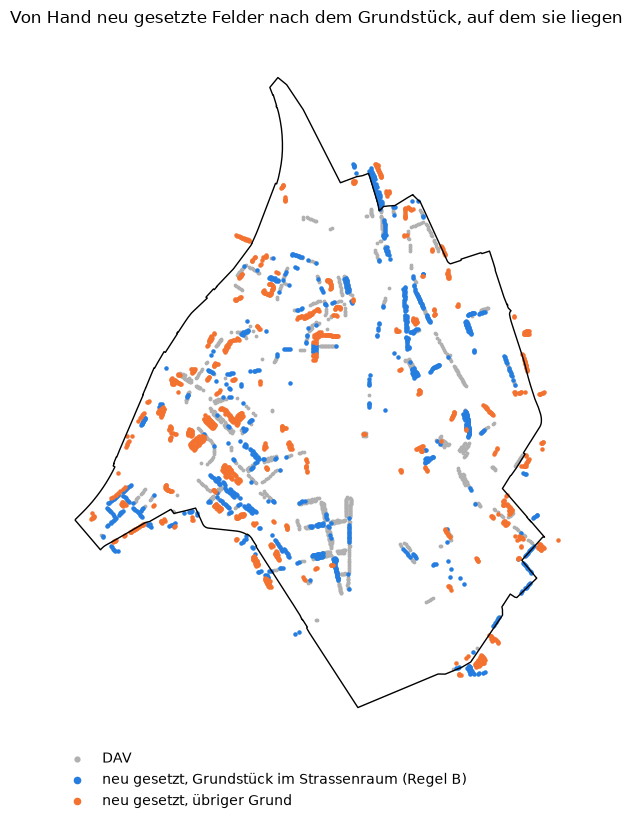

In [20]:
# Karte: die neu gesetzten Felder, gefärbt nach Regel B; dazu die DAV-Punkte in Grau
fig, ax = plt.subplots(figsize=(8, 9))
gebiet.boundary.plot(ax=ax, color="black", linewidth=1)
punkte[punkte.quelle == "DAV (amtliche Lage)"].plot(ax=ax, color="#b0b0b0", markersize=3, label="DAV")
neu_karte = punkte[punkte.quelle == "neu gesetzt"]
neu_karte[neu_karte.regel_B].plot(ax=ax, color="#257de0", markersize=5, label="neu gesetzt, Grundstück im Strassenraum (Regel B)")
neu_karte[~neu_karte.regel_B].plot(ax=ax, color="#f47230", markersize=5, label="neu gesetzt, übriger Grund")
ax.set_axis_off()
ax.legend(loc="upper left", bbox_to_anchor=(0, 0), frameon=False, markerscale=2)   # Legende unter die Karte
ax.set_title("Von Hand neu gesetzte Felder nach dem Grundstück, auf dem sie liegen")
fig.savefig(ABB / "gt_pruefung_grund.png", dpi=130, bbox_inches="tight")
plt.show()

**Was die Karte zeigt.** Grau: die DAV-Punkte. Blau: neu gesetzte Felder auf einem Grundstück, das überwiegend aus Strassenraum besteht. Orange: neu gesetzte Felder auf übrigem Grund, zum Beispiel in Innenhöfen. Weisse Stellen im Gebiet sind entweder ohne Parkfeld oder noch nicht abgeschlossen. Einzelne Felder liegen knapp ausserhalb des Gebiets, weil die Ausschnitte am Rand über die Grenze hinausreichen.

**Schritt 4: Gegenprobe mit amtlichen Daten.** Die Tabelle aus Schritt 3 zeigt nur, wie viele **DAV-Felder** eine Regel behält. Für die neu gesetzten Felder gibt es eine zweite Probe: Liegt nahe beim Feld ein **amtliches Objekt**? Drei amtliche Ebenen kommen in Frage:

| Ebene | Inhalt |
| --- | --- |
| Strassenparkplätze der Stadt, Stand 31.12.2021 | ein Punkt je öffentlich zugänglichem Platz |
| DAV-Punkte, Stand 2025 | alle 1'252 im Gebiet, auch gelöschte Vorschläge |
| Parkstreifen der DAV, Stand 2025 | Linien, z. B. Blaue Zone und Güterumschlag |

"Nahe" heisst hier höchstens 3 m (etwa eine halbe Feldlänge; der amtliche Punkt liegt oft nicht in der Feldmitte, siehe Abschnitt 3). Verglichen werden die neu gesetzten Felder **im Gebiet**, ohne Kontroll-Ausschnitte (dort wurden die DAV-Felder absichtlich neu gesetzt).

**Wie man die Tabelle liest.** Liegt bei den Feldern auf übrigem Grund fast nie ein amtliches Objekt, dann verliert Regel B dort kaum öffentliche Felder. Liegt bei den Feldern im Strassenraum meist eines, dann behält sie vor allem öffentliche.

Vorher: neu gesetzte Felder mit Regel B → nachher: dieselben Felder, je mit der Angabe "amtliches Objekt in 3 m: ja/nein".

In [21]:
NAH_M = 3.0                                                        # "nahe" = höchstens 3 m

plaetze_2021 = gpd.read_file(ROH / "parkplaetze/Strassenparkplaetze_OGD_2021_view_pp_ogd.geojson").to_crs(CRS).explode(index_parts=False)
streifen = gpd.read_file(ROH / "parkplaetze/DAV_oeff_strassenparkierung_dav_l.geojson").to_crs(CRS)     # Parkstreifen (Linien)

probe = punkte[(punkte.quelle == "neu gesetzt") & ~punkte.kachel.isin(kontroll_ids)]     # ohne Kontroll-Ausschnitte
probe = probe[probe.within(gebiet.geometry.iloc[0])].copy()                               # nur Felder im Gebiet
lage = np.column_stack([probe.geometry.x, probe.geometry.y])                              # x und y als Zahlenblock

abstand_2021, _ = cKDTree(np.column_stack([plaetze_2021.geometry.x, plaetze_2021.geometry.y])).query(lage)   # nächster Platz 2021
abstand_dav, _ = cKDTree(amtlich[["x", "y"]].values).query(lage)                          # nächster DAV-Punkt
abstand_streifen = probe.distance(streifen.union_all()).values                            # nächster Parkstreifen
probe["amtlich"] = np.where((abstand_2021 <= NAH_M) | (abstand_dav <= NAH_M) | (abstand_streifen <= NAH_M),
                            "amtliches Objekt in 3 m", "nichts Amtliches in 3 m")
probe["grund"] = np.where(probe.regel_B, "Strassenraum (Regel B)", "übriger Grund")

print(f"Vorher: {int((punkte.quelle == 'neu gesetzt').sum())} neu gesetzte Felder → nachher: {len(probe)} im Gebiet, ohne Kontroll-Ausschnitte")
display(pd.crosstab(probe.grund, probe.amtlich, margins=True, margins_name="alle"))
print("Dieselbe Auszählung nach Form, nur Strassenraum (Regel B):")
im_strassenraum = probe[probe.regel_B]
pd.crosstab(im_strassenraum.form, im_strassenraum.amtlich, margins=True, margins_name="alle")

Vorher: 2240 neu gesetzte Felder → nachher: 1592 im Gebiet, ohne Kontroll-Ausschnitte


amtlich,amtliches Objekt in 3 m,nichts Amtliches in 3 m,alle
grund,,,
Strassenraum (Regel B),432,192,624
übriger Grund,5,963,968
alle,437,1155,1592


Dieselbe Auszählung nach Form, nur Strassenraum (Regel B):


amtlich,amtliches Objekt in 3 m,nichts Amtliches in 3 m,alle
form,,,
Einzelfeld,242,76,318
Streifen ohne Einzelfelder,92,65,157
gelbes Feld mit Kreuz,98,50,148
unklar,0,1,1
alle,432,192,624


**Was die Gegenprobe nicht ist.** Sie ist kein Vergleich "Ground Truth gegen amtliche Zahl"; ein solches Delta steht erst am Schluss der Arbeit. Sie prüft nur, ob Regel B die von Hand gesetzten Felder so teilt, wie es die amtlichen Ebenen erwarten lassen. Die Felder im Strassenraum **ohne** amtliches Objekt sind die, die man einzeln ansehen sollte.

## Wie es weitergeht

- **Dieses Notebook entscheidet nichts.** Die zwei offenen Fragen (Parkart, öffentlich oder privat) stehen mit Möglichkeiten und Vorschlag in `01b`, Abschnitt 10.
- **Auffällige Ausschnitte** (übersehene Felder in Abschnitt 1, nicht gefundene Felder in Abschnitt 4) können im Werkzeug nochmals geöffnet werden: `http://127.0.0.1:8765/?kachel=<Name>`.
- **Danach** legt Notebook 02 fest, welche Blöcke zum Lernen, Validieren und Testen dienen – bevor ein Netz gelernt hat.